<a href="https://colab.research.google.com/github/Anastetikc/Math_Stat/blob/main/%D0%9A%D0%BE%D0%BF%D0%B8%D1%8F_%D0%B1%D0%BB%D0%BE%D0%BA%D0%BD%D0%BE%D1%82%D0%B0_%223_categorical_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sterolose/sirius-statistics-2026/blob/main/notebooks/3_categorical.ipynb)

## Семинар 3. Критерии согласия и категориальные данные

In [2]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

### Задание 1

При скрещивании двух гетерозигот `Aa` ожидаем генотипы `AA`, `Aa` и `aa` в соотношении 1:2:1. Это предполагает обычное менделевское наследование и одинаковую вероятность выживания и обнаружения всех генотипов. Генотипировали 200 независимо отобранных потомков.

In [3]:
df = pd.DataFrame({
    "probability": [0.25, 0.50, 0.25],
    "expected": [50, 100, 50],
    "observed": [46, 101, 53],
}, index=["AA", "Aa", "aa"])
df

,probability,expected,observed
AA,0.25,50,46
Aa,0.50,100,101
aa,0.25,50,53


Для оценки правдоподнобности получения такого распределения по генотипам может быть применен $χ^2$-критерий согласия Пирсона.

In [4]:
result = stats.chisquare(df["observed"], df["expected"])
pd.Series({
    "statistic": result.statistic,
    "p-value": result.pvalue,
})

,0
statistic,0.510000
p-value,0.774916


В другом скрещивании получили 64 особи `AA`, 98 — `Aa` и 38 — `aa`. Проверьте согласие со вторым законом Менделя.

In [5]:
obs = np.array([64, 98, 38])
total = obs.sum()
exp = np.array([0.25, 0.5, 0.25])*total


result = stats.chisquare(obs, exp)
pd.Series({
    "statistic": result.statistic,
    "p-value": result.pvalue,
})

,0
statistic,6.840000
p-value,0.032712


### Задание 2

В пилотном исследовании 40 пациентов с бактериальной инфекцией случайно разделили на две группы по 20 человек. Все получали стандартную терапию; в группе `Drug` дополнительно назначили экспериментальный препарат, в группе `Control` — плацебо. Через 7 дней оценили улучшение состояния по заранее заданному клиническому критерию. Каждая строка относится к отдельному пациенту, наблюдения в выборке независимы.

In [6]:
df = pd.DataFrame({
    "treatment": np.repeat(["Drug", "Drug", "Control", "Control"], [14, 6, 7, 13]),
    "outcome": np.repeat(["Improved", "Not improved", "Improved", "Not improved"], [14, 6, 7, 13]),
})
table = pd.crosstab(df["treatment"], df["outcome"])
table

outcome,Improved,Not improved
treatment,,
Control,7,13
Drug,14,6


Независимость исхода от лечения можно оценить с помощью `stats.chi2_contingency`.

In [7]:
result = stats.chi2_contingency(table)
pd.Series({
    "statistic": result.statistic,
    "p-value": result.pvalue,
})

,0
statistic,3.609023
p-value,0.057467


Было проведено исследование альтернативного препарата. Таблица сопряженности уже составлена. Повторите тест для нее. Отвергаем ли мы нулевую гипотезу при уровне значимости 0.05? А при 0.01?

In [8]:
table = pd.DataFrame(
    [[7, 13], [16, 4]],
    index=["Control", "Drug"],
    columns=["Improved", "Not improved"],
)
table

,Improved,Not improved
Control,7,13
Drug,16,4


In [9]:
result = stats.chi2_contingency(table)
pd.Series({
    "statistic": result.statistic,
    "p-value": result.pvalue,
})

,0
statistic,6.547315
p-value,0.010504


### Задание 3

Для той же таблицы применим точный тест Фишера. Тест не использует $χ^2$-приближение и подходит в том числе для малых ожидаемых численностей.

In [10]:
result = stats.fisher_exact(table)
pd.Series({
    "statistic": result.statistic,
    "p-value": result.pvalue,
})

,0
statistic,0.134615
p-value,0.009530


На малой выборке был исследован комбинированный препарат из первых двух лекарств. Используя приведенную таблицу сопряженности, выполните `chi2_contingency` и `fisher_exact`. Сравните результат. Почему вывод может расходиться?

In [11]:
table = pd.DataFrame(
    [[6, 3], [1, 8]],
    index=["Drug", "Control"],
    columns=["Improved", "Not improved"],
)
table

,Improved,Not improved
Drug,6,3
Control,1,8


In [12]:
chi2_res = stats.chi2_contingency(table)
fisher_res = stats.fisher_exact(table)

print(f"Chi2 p-value: {chi2_res.pvalue:.4f}")
print(f"Fisher p-value: {fisher_res.pvalue:.4f}")

Chi2 p-value: 0.0531
Fisher p-value: 0.0498


### Задание 4

Разработаем свой пермутационный тест. В качестве статистики возьмем разность долей улучшений:
$$\Delta = \hat p_{\mathrm{Drug}} - \hat p_{\mathrm{Control}}.$$

In [13]:
df = pd.DataFrame({
    "treatment": np.repeat(["Drug", "Drug", "Control", "Control"], [19, 11, 12, 18]),
    "outcome": np.repeat(["Improved", "Not improved", "Improved", "Not improved"],[19, 11, 12, 18]),
})
table = pd.crosstab(df["treatment"], df["outcome"])
table

outcome,Improved,Not improved
treatment,,
Control,12,18
Drug,19,11


In [14]:
treatment = df["treatment"]
improved = df["outcome"] == "Improved"

drug_rate = improved[treatment == "Drug"].mean()
control_rate = improved[treatment == "Control"].mean()
observed_difference = drug_rate - control_rate

pd.Series({
    "Drug improvement rate": drug_rate,
    "Control improvement rate": control_rate,
    "Difference": observed_difference,
})

,0
Drug improvement rate,0.633333
Control improvement rate,0.400000
Difference,0.233333


При нулевой гипотезе метки лечения обменяемы: их можно переставлять между пациентами, сохраняя исходы и размеры групп. В этом примере такую перестановку обосновывают случайное распределение по группам и независимость наблюдений. Осуществим одну случайную перестановку.

In [18]:
rng = np.random.default_rng(42)
shuffled_treatment = rng.permutation(treatment)

shuffled_difference = (
    improved[shuffled_treatment == "Drug"].mean()
    - improved[shuffled_treatment == "Control"].mean()
)

(round(observed_difference, 4), round(shuffled_difference, 4))

(np.float64(0.2333), np.float64(0.0333))

Осуществите 10000 перестановок, рассчитав для каждой значение статистики. Запишите их в список `permuted_differences`.

In [22]:
rng = np.random.default_rng(42)
n_permutations = 10000

permuted_differences = []
for _ in range(n_permutations):
  shuffled_treatment = rng.permutation(treatment)
  simulated_difference = (
        improved[shuffled_treatment == "Drug"].mean()
        - improved[shuffled_treatment == "Control"].mean()
    )
  permuted_differences.append(simulated_difference)

Постройте гистограмму `permuted_differences`. Добавьте вертикальные линии в точках `observed_difference` и `-observed_difference`. Где находится центр распределения? Насколько далеко от него наблюдаемый эффект?

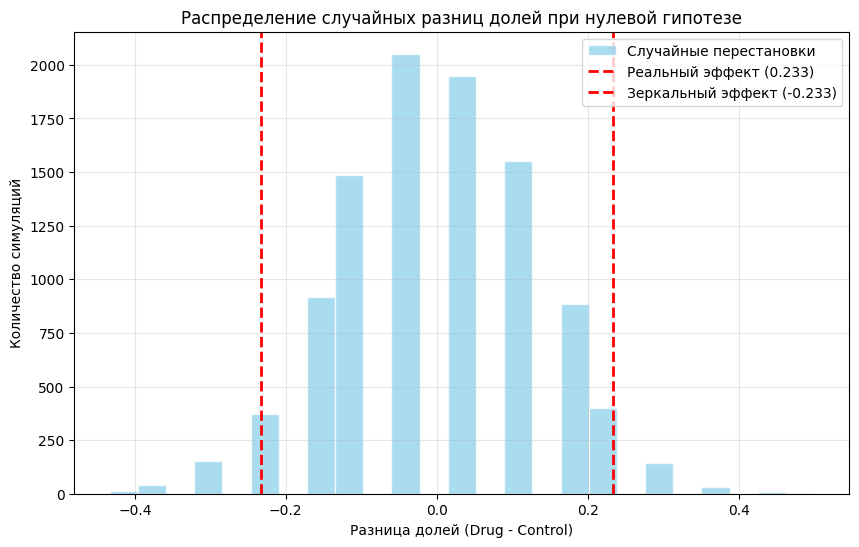

In [29]:
perm_diffs_arr = np.array(permuted_differences)

plt.figure(figsize=(10, 6))
plt.hist(perm_diffs_arr, bins=25, alpha=0.7, color="skyblue", edgecolor="white", label="Случайные перестановки")

plt.axvline(observed_difference, color="red", linestyle="dashed", linewidth=2, label=f"Реальный эффект ({observed_difference:.3f})")
plt.axvline(-observed_difference, color="red", linestyle="dashed", linewidth=2, label=f"Зеркальный эффект ({-observed_difference:.3f})")

plt.title("Распределение случайных разниц долей при нулевой гипотезе")
plt.xlabel("Разница долей (Drug - Control)")
plt.ylabel("Количество симуляций")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Для двустороннего теста посчитайте число перестановок $b$, для которых $|\Delta_{\mathrm{perm}}| \geq |\Delta_{\mathrm{obs}}|$. Оцените p-value по формуле:

$$\hat p = \frac{b+1}{10000+1}.$$

Сравните результат с тестом Фишера и $χ^2$-критерием.

In [27]:
b = np.sum(np.abs(perm_diffs_arr) >= np.abs(observed_difference))
p_value_perm = (b + 1) / (10000 + 1)

print(f"Число экстремальных перестановок (b): {b}")
print(f"Оценка p-value: {p_value_perm:.4f}")

Число экстремальных перестановок (b): 1164
Оценка p-value: 0.1165
